In [1]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


In [6]:
import numpy as np
import torch

# random res
random_res = np.loadtxt("data/random.txt")

# optuna 
optuna_res = np.loadtxt("data/optuna.txt")

# hebo
hebo_res = np.loadtxt("data/vanilla_hebo_A6.txt")

# tidyhebo
tidyhebo_res = np.loadtxt("data/tidyhebo_A6.txt")


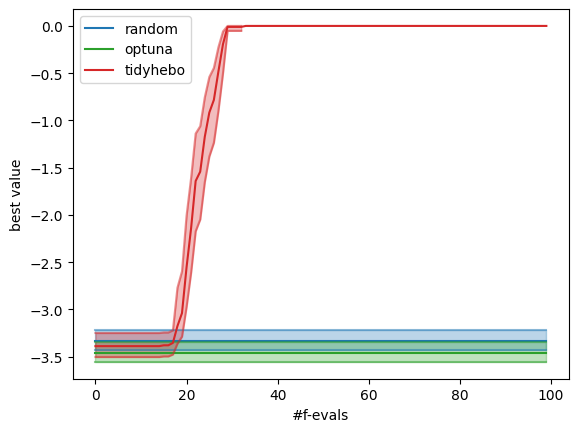

In [10]:
import matplotlib.pyplot as plt

ax = plt.gca()

tr = lambda x: x
# tr = lambda x: np.log10(optimization_got_max - x)

plot_selection_result(tr(random_res), ax, budget=100, label="random", color="tab:blue")
plot_selection_result(tr(optuna_res), ax, budget=100, label="optuna", color="tab:green")
# plot_selection_result(tr(hebo_res), ax, budget=100, label="hebo", color="tab:purple")
plot_selection_result(tr(tidyhebo_res), ax, budget=100, label="tidyhebo", color="tab:red")

ax.set_xlabel("#f-evals")
ax.set_ylabel("best value")

ax.legend();